<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# How close is the place selected by reverse geocoding?

A place name can look precise even when its coordinates are far from the input. We will resolve a small, deliberately chosen set of city-centre, offshore and Arctic coordinates through the real offline worker, measure each point-to-place distance, and vary a distance screen.

These are **authored demonstration coordinates**, not tracked people, measured GPS fixes or a representative sample. The worker uses bundled GeoNames place data and timezone polygons. [Running instructions](README.md) pin the code and data-bearing library versions.

## Set a proximity screen

`RADIUS_KM` accepts finite numbers from 1 to 2,000 kilometres. A resolved match passes when its great-circle distance from the input is **at most** this value. This is a chosen proximity rule, not a confidence probability or a territorial test. Change the parameter, restart the kernel and run all; the coordinate set and lookup indexes remain fixed.

In [1]:
RADIUS_KM = 50  # Inclusive point-to-selected-place distance screen; experiment: 500

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.ticker import FuncFormatter, MaxNLocator, NullFormatter

from notebook_support import chart, prose, theme, validate_radius

validate_radius(RADIUS_KM)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-geocode-portable-ibo8cjq9/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-geocode-portable-ibo8cjq9/pyproject.toml.

## Resolve explicit points through the published worker

No API or credential is involved. The literal Git-tag launcher runs the real worker from an isolated published-dependency environment. Input latitude/longitude are in **decimal degrees**, in that order. The SQL table includes one out-of-range latitude and one missing latitude so unavailable results stay visible.

The selected place’s country belongs to that gazetteer record. It does not establish which territory contains the input point. The separate timezone function uses the **input coordinate** against its own polygons; ocean results may be `Etc/GMT…` names.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'geocode' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with reverse-geocoder==1.5.1 --with timezonefinder==9.2.0 --with numpy==2.5.4 --with scipy==1.18.1 --from git+https://github.com/Query-farm/vgi-geocode@v0.4.0 vgi-geocode-worker');
CREATE TABLE points AS
SELECT id, label, kind, lat::DOUBLE AS lat, lon::DOUBLE AS lon
FROM (VALUES
    (1,'New York centre','City centre',40.7128,-74.0060),
    (2,'Paris centre','City centre',48.8566,2.3522),
    (3,'Tokyo centre','City centre',35.6762,139.6503),
    (4,'Atlantic offshore','Offshore',40.0,-73.0),
    (5,'Pacific offshore','Offshore',33.0,141.0),
    (6,'Mid-Atlantic point','Offshore',40.0,-30.0),
    (7,'Arctic point','Remote',85.0,0.0),
    (8,'Invalid latitude','Invalid input',95.0,0.0),
    (9,'Missing latitude','Missing input',NULL,0.0)
) AS t(id,label,kind,lat,lon);
CREATE TABLE resolved AS
SELECT *, geocode.reverse_geocode(lat,lon) AS place FROM points;
CREATE TABLE enriched AS
SELECT *, geocode.timezone(lat,lon) AS point_timezone,
       geocode.country_code(lat,lon) AS scalar_place_country
FROM resolved;
CREATE TABLE measured AS
SELECT *, geocode.distance_km(lat,lon,place.place_lat,place.place_lon) AS separation_km
FROM enriched;

Running query in 'DuckDBPyConnection'

9 rows affected.

9 rows affected.

9 rows affected.

9 rows affected.

,Count


## Audit the selected match

The pinned `reverse_geocoder` 1.5.1 constructs and queries its KD-tree directly in latitude/longitude degree coordinates. That selection is **not guaranteed to minimize great-circle distance**, especially near poles or the antimeridian. We audit the returned match rather than asserting it is the geodesically nearest city.

The distance function uses a spherical haversine model with radius **6,371.0088 km**. It is point-to-point separation, not a travel route or an ellipsoidal survey measurement. The SQL expression below independently checks that formula. Invalid or missing coordinates keep NULL place, timezone and distance values.

In [4]:
%%sql
CREATE TABLE audit AS
SELECT *,
       coalesce(isfinite(lat) AND isfinite(lon) AND abs(lat)<=90 AND abs(lon)<=180,FALSE) AS valid_coordinate,
       CASE WHEN place IS NULL THEN NULL ELSE 2*6371.0088*asin(sqrt(least(1.0,greatest(0.0,
           pow(sin(radians(place.place_lat-lat)/2),2)
           + cos(radians(lat))*cos(radians(place.place_lat))
             *pow(sin(radians(place.place_lon-lon)/2),2))))) END AS sql_distance_km,
       CASE WHEN lat IS NULL OR lon IS NULL THEN 'Missing input'
            WHEN NOT isfinite(lat) OR NOT isfinite(lon) OR abs(lat)>90 OR abs(lon)>180 THEN 'Invalid input'
            WHEN place IS NULL OR separation_km IS NULL THEN 'Lookup unavailable'
            WHEN separation_km <= {{ RADIUS_KM }} THEN 'Within screen'
            ELSE 'Beyond screen' END AS screen_status
FROM measured;
CREATE TABLE availability AS
SELECT count(*) AS input_points,
       count(*) FILTER (WHERE valid_coordinate) AS valid_points,
       count(*) FILTER (WHERE place IS NOT NULL) AS returned_places,
       count(*) FILTER (WHERE point_timezone IS NOT NULL) AS returned_timezones,
       count(*) FILTER (WHERE screen_status='Missing input') AS missing_inputs,
       count(*) FILTER (WHERE screen_status='Invalid input') AS invalid_inputs,
       count(*) FILTER (WHERE screen_status='Lookup unavailable') AS lookup_unavailable,
       count(*) FILTER (WHERE screen_status='Within screen') AS within_screen,
       count(*) FILTER (WHERE screen_status='Beyond screen') AS beyond_screen
FROM audit;

Running query in 'DuckDBPyConnection'

9 rows affected.

1 rows affected.

,Count


In [5]:
%%sql availability_frame <<
SELECT * FROM availability;

Running query in 'DuckDBPyConnection'

In [6]:
%%sql matches <<
SELECT id, label, kind, lat, lon, place.city AS selected_place,
       place.country_code AS place_country, point_timezone, separation_km, screen_status
FROM audit ORDER BY id;

Running query in 'DuckDBPyConnection'

In [7]:
display(availability_frame)
display(matches)
a = availability_frame.iloc[0]
prose(
    f"Of **{int(a.input_points)} inputs**, **{int(a.returned_places)}** return a place and "
    f"**{int(a.within_screen)}** pass the **{RADIUS_KM:g} km** screen. "
    f"There are **{int(a.invalid_inputs)} invalid** and **{int(a.missing_inputs)} missing** inputs; "
    "neither is a zero-distance match. A country label and an ocean timezone name can coexist "
    "because the two lookups describe different things."
)

,input_points,valid_points,returned_places,returned_timezones,missing_inputs,invalid_inputs,lookup_unavailable,within_screen,beyond_screen
0,9,7,7,7,1,1,0,3,4


,id,label,kind,lat,lon,selected_place,place_country,point_timezone,separation_km,screen_status
0,1,New York centre,City centre,40.7128,-74.0060,New York City,US,America/New_York,0.163476,Within screen
1,2,Paris centre,City centre,48.8566,2.3522,Paris,FR,Europe/Paris,0.433242,Within screen
2,3,Tokyo centre,City centre,35.6762,139.6503,Tokyo,JP,Asia/Tokyo,4.021888,Within screen
3,4,Atlantic offshore,Offshore,40.0000,-73.0000,West Sayville,US,Etc/GMT+5,81.358066,Beyond screen
4,5,Pacific offshore,Offshore,33.0000,141.0000,Katsuura,JP,Etc/GMT-9,246.523289,Beyond screen
5,6,Mid-Atlantic point,Offshore,40.0000,-30.0000,Ribeira Grande,PT,Etc/GMT+2,199.324911,Beyond screen
6,7,Arctic point,Remote,85.0000,0.0000,Olonkinbyen,SJ,Etc/GMT,1573.992134,Beyond screen
7,8,Invalid latitude,Invalid input,95.0000,0.0000,None,None,None,NaN,Invalid input
8,9,Missing latitude,Missing input,NaN,0.0000,None,None,None,NaN,Missing input


Of **9 inputs**, **7** return a place and **3** pass the **50 km** screen. There are **1 invalid** and **1 missing** inputs; neither is a zero-distance match. A country label and an ocean timezone name can coexist because the two lookups describe different things.

A name alone hides the scale of the displacement. This chart includes only measured positive separations on a logarithmic axis; exact zero-distance matches, if any, are reported separately. Missing results remain in the table above. Colour shows only whether the chosen distance screen passes.

findfont: Failed to find font weight semibold for Arial, now using 700.


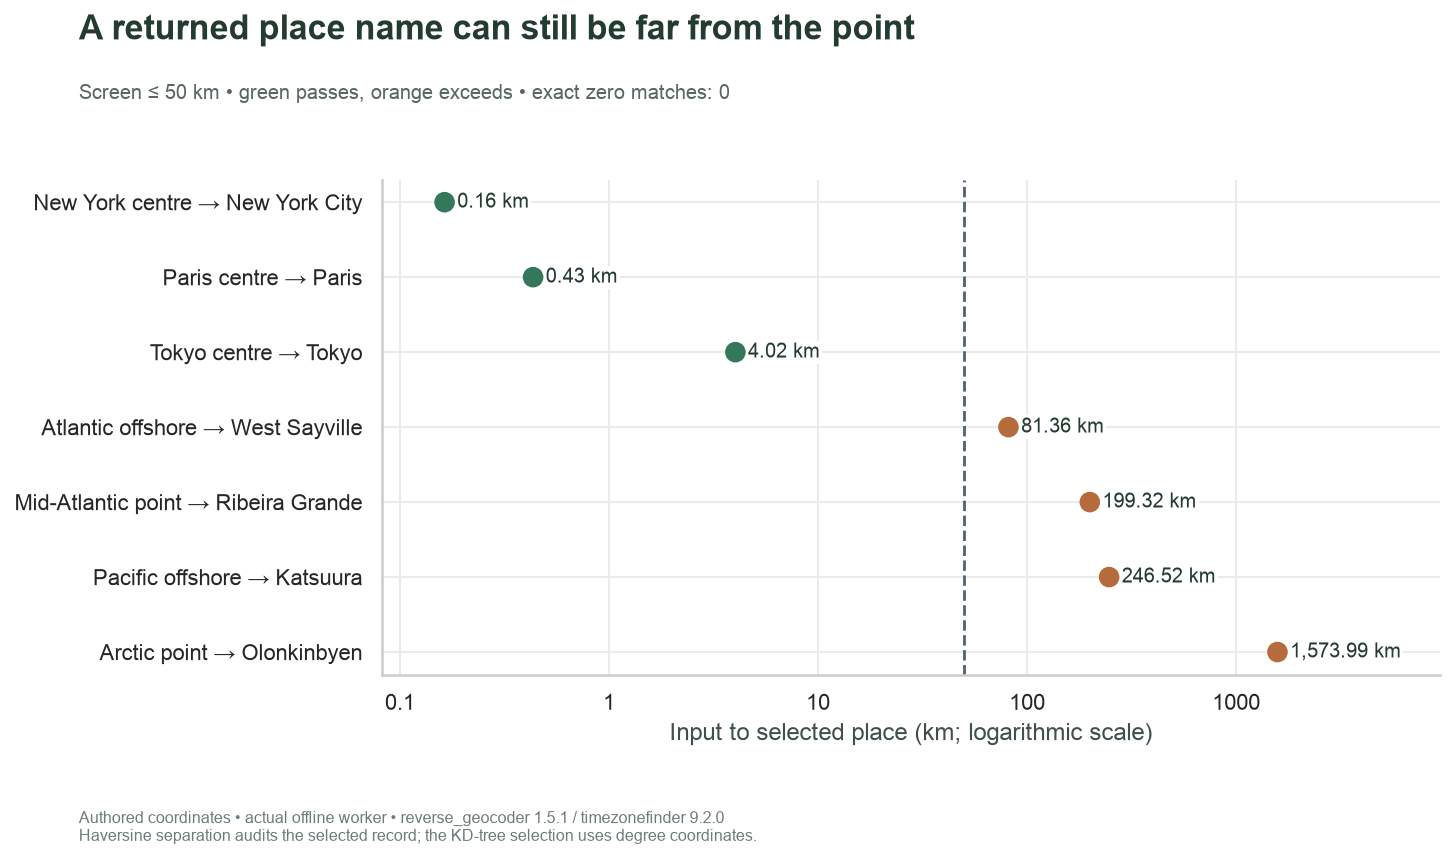

In [8]:
distances = matches.loc[matches.separation_km.gt(0)].sort_values("separation_km")
zero_count = int(matches.separation_km.eq(0).sum())
fig, ax = plt.subplots(figsize=(10.4, 6))
y = np.arange(len(distances))
colors = ["#34785B" if s == "Within screen" else "#B66B3D" for s in distances.screen_status]
ax.scatter(distances.separation_km, y, s=85, color=colors, zorder=3)
for i, row in enumerate(distances.itertuples()):
    ax.text(
        row.separation_km * 1.15,
        i,
        f"{row.separation_km:,.2f} km",
        va="center",
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.95, "pad": 1},
    )
ax.axvline(RADIUS_KM, color="#536077", linestyle="--", linewidth=1.4)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlim(
    min(distances.separation_km.min(), RADIUS_KM) / 2, max(distances.separation_km.max(), RADIUS_KM) * 6
)
ax.set_yticks(y, [f"{r.label} → {r.selected_place}" for r in distances.itertuples()])
ax.invert_yaxis()
ax.set_xlabel("Input to selected place (km; logarithmic scale)")
chart(
    fig,
    "A returned place name can still be far from the point",
    f"Screen ≤ {RADIUS_KM:g} km • green passes, orange exceeds • exact zero matches: {zero_count}",
    "Authored coordinates • actual offline worker • reverse_geocoder 1.5.1 / timezonefinder 9.2.0\n"
    "Haversine separation audits the selected record; the KD-tree selection uses degree coordinates.",
)

In [9]:
farthest = matches.loc[matches.separation_km.notna()].sort_values("separation_km").iloc[-1]
prose(
    f"The most separated returned match is **{farthest.label} → {farthest.selected_place}**, "
    f"about **{farthest.separation_km:,.0f} km** away. "
    "This is evidence about the selected gazetteer record, not proof that no closer settlement exists. "
    "Passing the screen also does not establish land/water status, jurisdiction or positional accuracy."
)

The most separated returned match is **Arctic point → Olonkinbyen**, about **1,574 km** away. This is evidence about the selected gazetteer record, not proof that no closer settlement exists. Passing the screen also does not establish land/water status, jurisdiction or positional accuracy.

## Sweep the distance screen without repeating lookups

We reuse the materialized distances. The exact step curve changes only at observed separations; it shows how many of these resolved points pass each radius between 1 and 2,000 km. Adding a looser screen can increase this sample’s coverage, but it cannot make the returned labels more accurate. The two invalid/missing inputs never enter the denominator.

In [10]:
%%sql sensitivity <<
WITH radii AS (
    SELECT radius_km FROM (VALUES (1.0),(2000.0),({{ RADIUS_KM }}::DOUBLE)) t(radius_km)
    UNION SELECT separation_km FROM audit WHERE separation_km BETWEEN 1 AND 2000
)
SELECT radius_km, count(*) FILTER (WHERE a.separation_km<=r.radius_km) AS passing_points,
       count(a.separation_km) AS resolved_points
FROM radii r CROSS JOIN audit a GROUP BY radius_km ORDER BY radius_km;

Running query in 'DuckDBPyConnection'

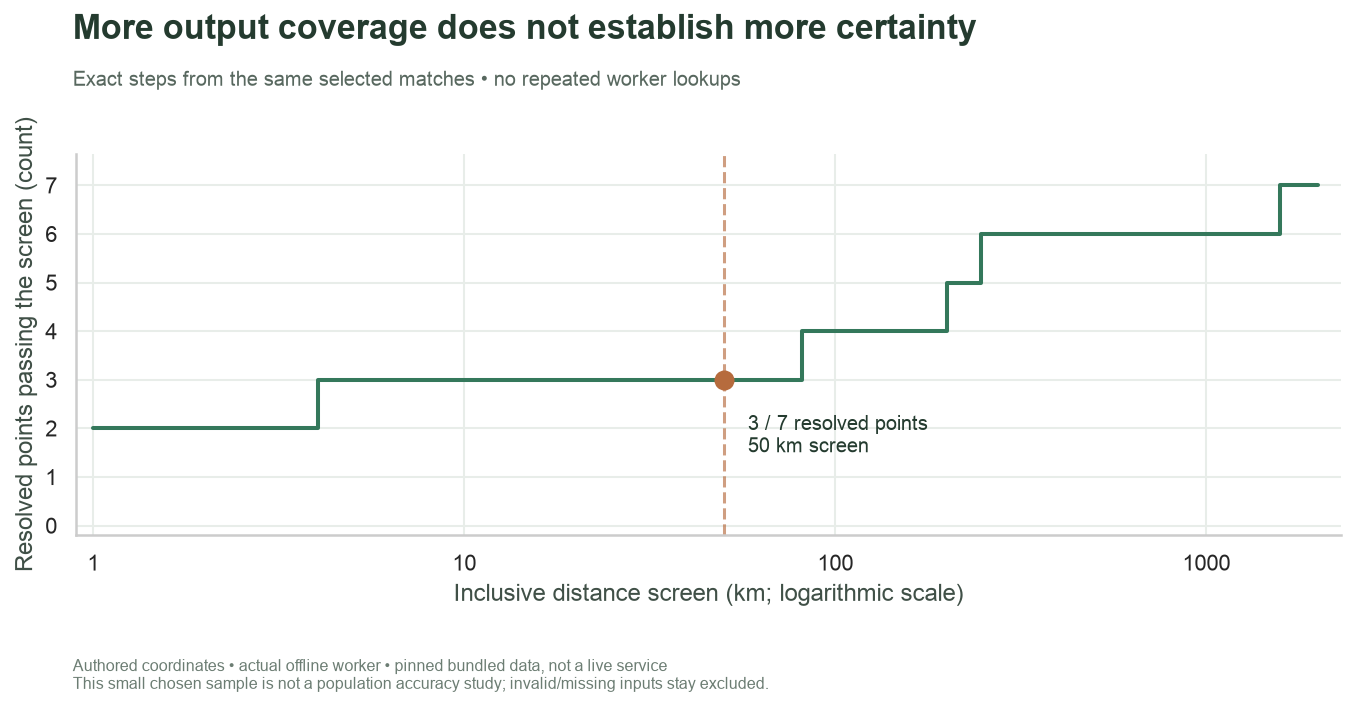

In [11]:
fig, ax = plt.subplots(figsize=(9.7, 4.9))
ax.step(sensitivity.radius_km, sensitivity.passing_points, where="post", color="#34785B", linewidth=2)
ax.scatter([RADIUS_KM], [a.within_screen], color="#B66B3D", s=80, zorder=4)
ax.axvline(RADIUS_KM, color="#B66B3D", linestyle="--", alpha=0.65)
ax.annotate(
    f"{int(a.within_screen)} / {int(a.returned_places)} resolved points\n{RADIUS_KM:g} km screen",
    (RADIUS_KM, a.within_screen),
    xytext=((-12, 18 if a.within_screen < a.returned_places else -36) if RADIUS_KM > 200 else (12, -36)),
    ha=("right" if RADIUS_KM > 200 else "left"),
    textcoords="offset points",
    fontsize=10,
)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(0.9, 2300)
ax.set_ylim(-0.2, a.returned_places + 0.65)
ax.set_xlabel("Inclusive distance screen (km; logarithmic scale)")
ax.set_ylabel("Resolved points passing the screen (count)")
chart(
    fig,
    "More output coverage does not establish more certainty",
    "Exact steps from the same selected matches • no repeated worker lookups",
    "Authored coordinates • actual offline worker • pinned bundled data, not a live service\n"
    "This small chosen sample is not a population accuracy study; invalid/missing inputs stay excluded.",
)

## Verify the measurement contract

Checks below cover input/result correspondence, NULL propagation, coordinate and distance bounds, agreement between the STRUCT and scalar country outputs, independent haversine arithmetic, and monotonic threshold counts. They do not require a particular city ranking or claim that nearest-place labels are point-in-polygon answers.

In [12]:
%%sql checks <<
SELECT 'One returned row per input identifier' AS check_name,
       (SELECT count(*)=count(DISTINCT id) FROM audit)
       AND (SELECT count(*) FROM audit)=(SELECT count(*) FROM points) AS passed
UNION ALL SELECT 'Invalid and missing inputs preserve NULL results',
       NOT EXISTS (SELECT 1 FROM audit WHERE NOT valid_coordinate
                   AND (place IS NOT NULL OR point_timezone IS NOT NULL OR separation_km IS NOT NULL OR sql_distance_km IS NOT NULL))
UNION ALL SELECT 'Valid lookups return a place with geographic coordinates',
       NOT EXISTS (SELECT 1 FROM audit WHERE valid_coordinate
                   AND (place IS NULL OR place.place_lat IS NULL OR place.place_lon IS NULL OR NOT isfinite(place.place_lat) OR NOT isfinite(place.place_lon)
                        OR abs(place.place_lat)>90 OR abs(place.place_lon)>180))
UNION ALL SELECT 'Selected-place country agrees across worker outputs',
       NOT EXISTS (SELECT 1 FROM audit WHERE place.country_code IS DISTINCT FROM scalar_place_country)
UNION ALL SELECT 'Known distances lie within spherical bounds',
       NOT EXISTS (SELECT 1 FROM audit WHERE separation_km IS NOT NULL
                   AND (NOT isfinite(separation_km) OR separation_km<0 OR separation_km>pi()*6371.0088))
UNION ALL SELECT 'Worker haversine agrees with independent SQL formula',
       NOT EXISTS (SELECT 1 FROM audit WHERE valid_coordinate
                   AND (separation_km IS NULL OR sql_distance_km IS NULL OR abs(separation_km-sql_distance_km)>1e-8))
UNION ALL SELECT 'Screen status agrees with inclusive radius',
       NOT EXISTS (SELECT 1 FROM audit WHERE separation_km IS NOT NULL
                   AND (screen_status='Within screen')<>(separation_km<={{ RADIUS_KM }}))
UNION ALL SELECT 'Available screen classes partition the input set',
       (SELECT input_points=missing_inputs+invalid_inputs+lookup_unavailable+within_screen+beyond_screen
        FROM availability)
UNION ALL SELECT 'At least one valid measured point is available',
       (SELECT count(separation_km)>0 FROM audit);

Running query in 'DuckDBPyConnection'

In [13]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert sensitivity.passing_points.is_monotonic_increasing
assert sensitivity.resolved_points.eq(a.returned_places).all()
prose("All nine SQL invariants and the monotonic/resolved-denominator curve checks passed.")

,check_name,passed
0,One returned row per input identifier,True
1,Invalid and missing inputs preserve NULL results,True
2,Valid lookups return a place with geographic c...,True
3,Selected-place country agrees across worker ou...,True
4,Known distances lie within spherical bounds,True
5,Worker haversine agrees with independent SQL f...,True
6,Screen status agrees with inclusive radius,True
7,Available screen classes partition the input set,True
8,At least one valid measured point is available,True


All nine SQL invariants and the monotonic/resolved-denominator curve checks passed.

## Experiment: relax only the radius

Change **`RADIUS_KM = 50` to `500`**, restart and run all, or use the README’s separate-output command. Predict which orange points will turn green and compare the selected place names, distances, availability counts and marked step-curve position.

The radius must not alter the worker’s lookups or distances; it changes only the screen. A looser rule can admit offshore points with land-place labels, so proximity alone cannot certify a country or a geocoding confidence level. An application needing containment or navigational accuracy requires a different data/model contract. Reset **`RADIUS_KM = 50`** for the saved default.

In [14]:
connection.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>